# Synthetic Data Generation using FairGAN

This notebook implements a FairGAN model to generate synthetic data.

The objective is to compare FairGAN with non-fair models in terms of:
- Data quality
- Preservation of statistical properties
- Fairness across sensitive attributes

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

## Dataset

We use the Adult Income dataset which is our test data.

In [10]:
df = pd.read_csv("test_data/adult.csv")

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Data Preprocessing

We define categorical variables and clean the dataset.

In [11]:
df = df.replace('?', np.nan).dropna()
df.columns = [col.strip() for col in df.columns]

# Encode categorical variables
df_encoded = df.copy()

for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        df_encoded[col] = LabelEncoder().fit_transform(df_encoded[col])

### Define Sensitive and Target

In [12]:
S = 'sex'
Y = 'income'

S_index = df_encoded.columns.get_loc(S)
Y_index = df_encoded.columns.get_loc(Y)

## FairGAN Model
### Model Architecture

FairGAN consists of:
- Generator
- Discriminator
- Fairness discriminator

In [13]:
input_dim = df_encoded.shape[1]
noise_dim = 100

#Generator
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(noise_dim, 128),
            nn.ReLU(),
            nn.Linear(128, input_dim)
        )

    def forward(self, z):
        return self.model(z)
    

# Real/Fake Discriminator (D1)
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

# Fairness Discriminator (D2)
class FairnessDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)    

### Model Initialization

In [14]:
G = Generator()
D1 = Discriminator()
D2 = FairnessDiscriminator()

criterion = nn.BCELoss()

g_optimizer = optim.Adam(G.parameters(), lr=0.001)
d1_optimizer = optim.Adam(D1.parameters(), lr=0.001)
d2_optimizer = optim.Adam(D2.parameters(), lr=0.001)

data = torch.tensor(df_encoded.values, dtype=torch.float32)

epochs = 200
lambda_fair = 0.5

## FairGAN Model Training

In [15]:
for epoch in range(epochs):

    # Train D1 (real vs fake)
    real_labels = torch.ones(len(data), 1)
    fake_labels = torch.zeros(len(data), 1)

    z = torch.randn(len(data), noise_dim)
    fake_data = G(z)

    d1_real = D1(data)
    d1_fake = D1(fake_data.detach())

    d1_loss = criterion(d1_real, real_labels) + \
              criterion(d1_fake, fake_labels)

    d1_optimizer.zero_grad()
    d1_loss.backward()
    d1_optimizer.step()


    # Train D2 (predict S)
    S_real = data[:, S_index].unsqueeze(1)

    d2_pred = D2(data)
    d2_loss = criterion(d2_pred, S_real)

    d2_optimizer.zero_grad()
    d2_loss.backward()
    d2_optimizer.step()


    # Train Generator
    z = torch.randn(len(data), noise_dim)
    fake_data = G(z)


    #GAN loss (fool D1)
    g_loss = criterion(D1(fake_data), real_labels)

    #FAIRNESS loss (Xu-style)
    S_fake_pred = D2(fake_data)

    # push D2 to be uncertain (0.5)
    target_uncertain = torch.full_like(S_fake_pred, 0.5)
    fair_loss = criterion(S_fake_pred, target_uncertain)

    #TOTAL LOSS
    total_g_loss = g_loss - lambda_fair * fair_loss

    g_optimizer.zero_grad()
    total_g_loss.backward()
    g_optimizer.step()

    if epoch % 10 == 0:
        print(f"Epoch {epoch} | D1: {d1_loss.item():.4f} | D2: {d2_loss.item():.4f} | G: {g_loss.item():.4f} | Fair: {fair_loss.item():.4f}")

Epoch 0 | D1: 100.1996 | D2: 33.3958 | G: 0.7445 | Fair: 0.6942
Epoch 10 | D1: 0.7190 | D2: 33.1518 | G: 0.6757 | Fair: 0.6938
Epoch 20 | D1: 0.6966 | D2: 33.1518 | G: 0.7046 | Fair: 0.6942
Epoch 30 | D1: 0.6542 | D2: 33.1518 | G: 0.7632 | Fair: 0.6970
Epoch 40 | D1: 0.6518 | D2: 33.1518 | G: 0.8051 | Fair: 0.7016
Epoch 50 | D1: 0.6917 | D2: 33.1518 | G: 0.7792 | Fair: 0.7108
Epoch 60 | D1: 0.8065 | D2: 33.1518 | G: 0.7759 | Fair: 0.7243
Epoch 70 | D1: 0.7830 | D2: 33.1518 | G: 0.8400 | Fair: 0.7495
Epoch 80 | D1: 0.7287 | D2: 33.1518 | G: 0.8780 | Fair: 0.7568
Epoch 90 | D1: 0.6288 | D2: 33.1518 | G: 0.9320 | Fair: 0.7455
Epoch 100 | D1: 0.6029 | D2: 33.1518 | G: 0.9315 | Fair: 0.7288
Epoch 110 | D1: 0.5300 | D2: 33.1518 | G: 1.0677 | Fair: 0.7187
Epoch 120 | D1: 0.5526 | D2: 33.1518 | G: 0.9837 | Fair: 0.7138
Epoch 130 | D1: 0.5374 | D2: 33.1518 | G: 1.0374 | Fair: 0.7282
Epoch 140 | D1: 0.6457 | D2: 33.1518 | G: 0.9188 | Fair: 0.7645
Epoch 150 | D1: 0.8655 | D2: 33.1518 | G: 0.8140 

## Synthetic Data Generation

In [18]:
z = torch.randn(len(data), noise_dim)
synthetic = G(z).detach().numpy()

fake_df = pd.DataFrame(synthetic, columns=df_encoded.columns)

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Distribution Comparison

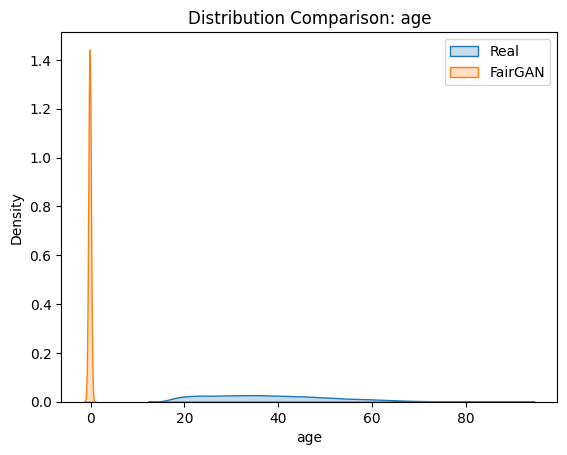

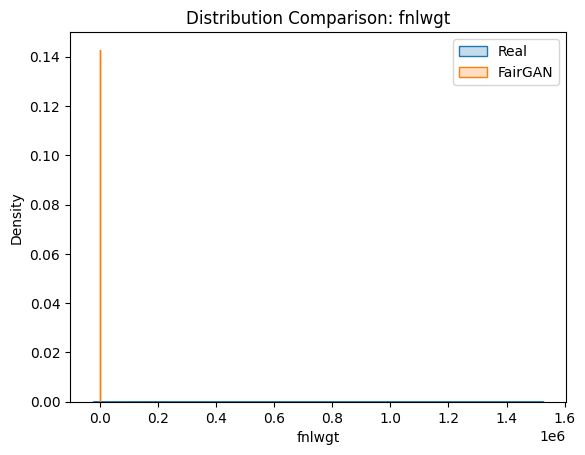

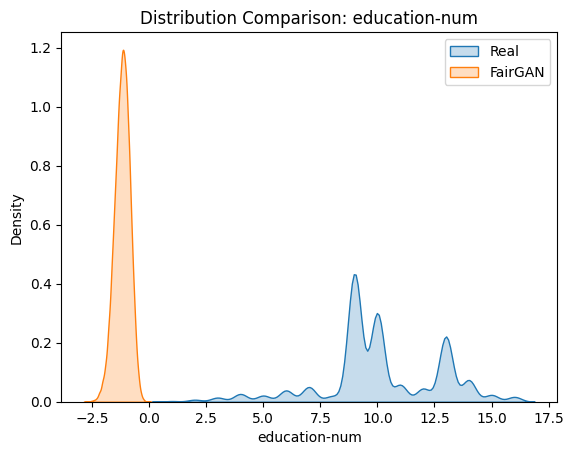

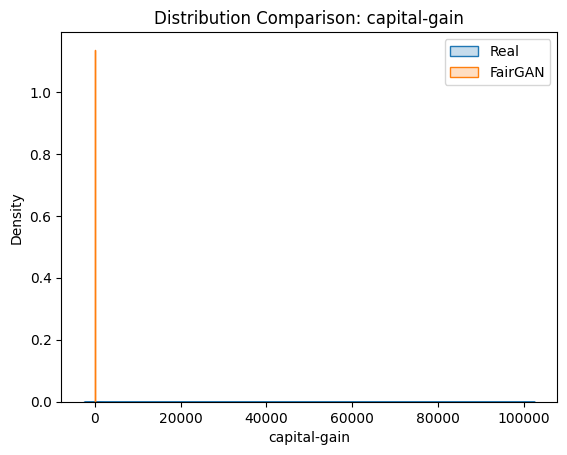

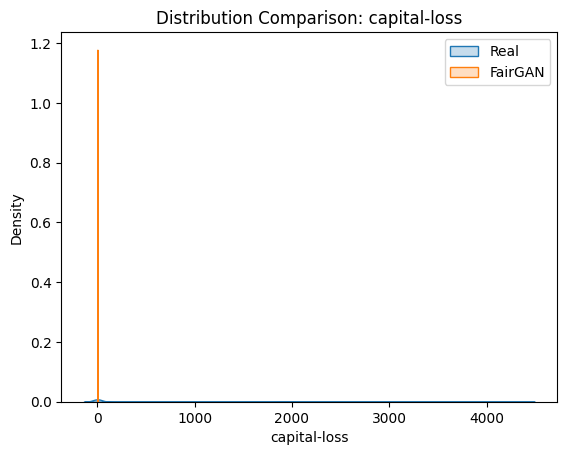

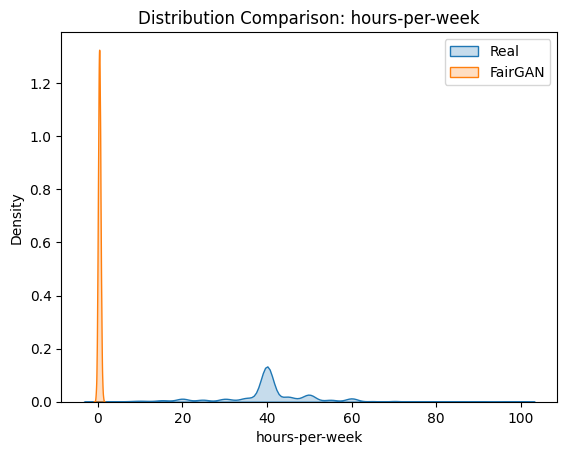

In [20]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    if col in fake_df.columns:  # safety check
        plt.figure()
        
        sns.kdeplot(df[col], label="Real", fill=True)
        sns.kdeplot(fake_df[col], label="FairGAN", fill=True)

        plt.title(f"Distribution Comparison: {col}")
        plt.legend()
        plt.show()

## Fairness Evaluation

In [25]:
#Convert income to binary
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
fake_df['income_binary'] = (fake_df['income'] > 0.5).astype(int)

df['sex_binary'] = df['sex'].apply(lambda x: 1 if 'Male' in x else 0)
fake_df['sex_binary'] = (fake_df['sex'] > 0.5).astype(int)

In [26]:
#Statistical Parity
def statistical_parity(df, sensitive_col, outcome_col):
    group_rates = df.groupby(sensitive_col)[outcome_col].mean()
    return group_rates.max() - group_rates.min(), group_rates

real_spd, real_rates = statistical_parity(df, 'sex_binary', 'income_binary')
fake_spd, fake_rates = statistical_parity(fake_df, 'sex_binary', 'income_binary')

print("REAL SPD:", real_spd)
print(real_rates)

print("\nFAKE SPD (FairGAN):", fake_spd)
print(fake_rates)

REAL SPD: 0.19451574596420296
sex_binary
0    0.109251
1    0.303767
Name: income_binary, dtype: float64

FAKE SPD (FairGAN): 0.019750495571110638
sex_binary
0    0.046059
1    0.065809
Name: income_binary, dtype: float64


In [27]:
#Disparity Gap
def disparate_impact(df, sensitive_col, outcome_col):
    group_rates = df.groupby(sensitive_col)[outcome_col].mean()
    return group_rates.min() / group_rates.max()

real_di = disparate_impact(df, 'sex_binary', 'income_binary')
fake_di = disparate_impact(fake_df, 'sex_binary', 'income_binary')

print("REAL DI:", real_di)
print("FAKE DI (FairGAN):", fake_di)

REAL DI: 0.3596552625800337
FAKE DI (FairGAN): 0.6998815672991384


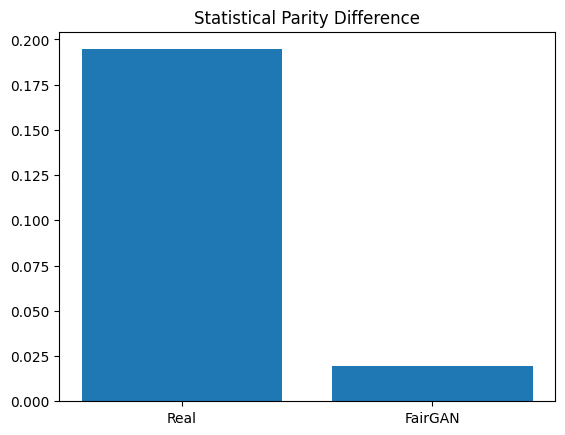

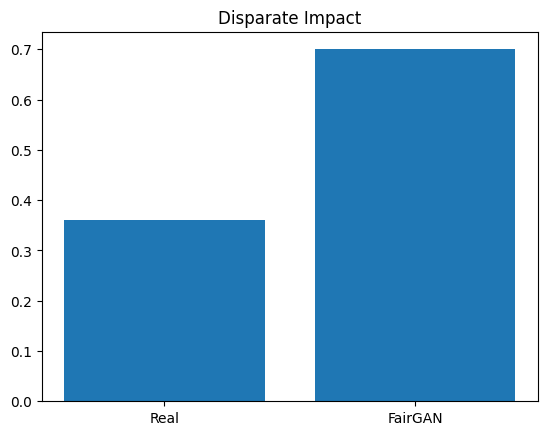

In [28]:
import matplotlib.pyplot as plt

labels = ['Real', 'FairGAN']
spd_values = [real_spd, fake_spd]
di_values = [real_di, fake_di]

plt.figure()
plt.bar(labels, spd_values)
plt.title("Statistical Parity Difference")
plt.show()

plt.figure()
plt.bar(labels, di_values)
plt.title("Disparate Impact")
plt.show()